In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load in 


# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list the files in the input directory

import os
print(os.listdir("../input"))

# Any results you write to the current directory are saved as output.

['IRIS.csv']



# Support Vector Machine (SVM)

## 1. Introduction

Support Vector Machine (SVM) is a supervised machine learning algorithm used for classification and regression.

The classification version is called Support Vector Classifier, and the regression version is called Support Vector Regression (SVR).

SVM tries to find the best decision boundary that separates different classes of data.

Unlike algorithms that simply find a boundary between classes, SVM aims to find a boundary with the **maximum margin** between the classes.

### Main objective
Find an optimal hyperplane that separates classes while maximizing the margin, with an appropriate penalty for margin violations when using a soft-margin SVM.

### Applications
- Spam email classification
- Sentiment analysis
- Image classification
- Text classification
- Medical diagnosis
- Handwriting recognition



## 2. Important Terminologies in SVM

### 1. Hyperplane
A hyperplane is the decision boundary that separates classes.

- In 2D, it is a line.
- In 3D, it is a plane.
- In higher dimensions, it is called a hyperplane.

### 2. Support Vectors
Support vectors are the training data points closest to the decision boundary or involved in defining the margin.

They are important because they determine the position and orientation of the SVM boundary.

### 3. Margin
The margin is the distance between the decision boundary and the nearest points from the two classes.

SVM attempts to maximize this margin.

### 4. Maximum Margin Classifier
A classifier that chooses the separating hyperplane with the largest possible margin under the specified constraints.

### 5. Decision Boundary
The boundary used to separate classes and make predictions for unseen data.

**Remember:** Support vectors determine the boundary, and the margin measures the separation around it.



## 3. How Does SVM Work?

1. Take the labelled training dataset.
2. Identify a suitable separating hyperplane.
3. Find the support vectors near the boundary.
4. Maximize the margin while accounting for classification errors when necessary.
5. Use the learned decision boundary to classify new observations.

### Hard Margin SVM

Hard Margin SVM assumes that the training data is perfectly linearly separable.

- Does not allow margin violations.
- Requires perfectly separable training data.
- Can be highly sensitive to outliers.
- Is not suitable for overlapping classes.

### Soft Margin SVM

Soft Margin SVM allows some observations to violate the margin or be misclassified.

- Works with overlapping classes.
- Uses a regularization parameter called C.
- Balances margin maximization and training errors.
- Is more practical for real-world datasets.

**Key difference:** Hard margin requires perfect separation; soft margin permits violations to achieve a better trade-off between margin size and classification errors.



## 4. Mathematical Intuition Behind SVM

A linear decision boundary can be represented as:

w · x + b = 0

Where:

- w = weight vector
- x = input feature vector
- b = bias or intercept

The prediction depends on which side of the hyperplane a point lies.

For binary classification:

- w · x + b > 0 → one class
- w · x + b < 0 → the other class

### Distance from a point to the hyperplane

The perpendicular distance is:

Distance = |w · x + b| / ||w||

For a standard linear SVM with canonical margin constraints, the margin width is:

Margin = 2 / ||w||

Therefore, maximizing the margin is equivalent to minimizing:

(1/2) ||w||²

### Soft-margin optimization

The soft-margin objective is:

Minimize:

(1/2) ||w||² + C Σ ξᵢ

Subject to:

yᵢ(w · xᵢ + b) ≥ 1 − ξᵢ

ξᵢ ≥ 0

Here:

- yᵢ = class label, usually −1 or +1
- ξᵢ = slack variable representing a margin violation
- C = regularization parameter

This objective balances a large margin against margin violations and misclassification.



## 5. Why Do We Need the Kernel Trick?

A linear SVM works when a straight line or hyperplane can separate the classes reasonably well.

However, many datasets have nonlinear patterns.

For example, consider a dataset containing two concentric circles:

- Class 0 is located near the centre.
- Class 1 surrounds Class 0.

No single straight line can correctly separate these two classes.

### Solution: Kernel Trick

The kernel trick allows SVM to learn nonlinear decision boundaries by computing similarities between data points as if they were mapped into a higher-dimensional feature space.

In that transformed space, a linear separating hyperplane may become possible.

When viewed in the original feature space, the resulting decision boundary can be nonlinear.

### Why is it called a trick?

Explicitly transforming every observation into a large, possibly high-dimensional feature space can be computationally expensive.

A kernel function computes the required inner products in that feature space directly, without explicitly constructing the transformed feature vectors.

This is known as the **kernel trick**.

**Important:** The kernel trick changes the similarity calculation used by SVM; it is not simply a method for drawing a curve.



## 6. Types of Kernels in SVM

A kernel function computes a similarity measure corresponding to an inner product in a feature space.

### 1. Linear Kernel

Formula:

K(x, z) = x · z

- Suitable when a linear boundary is appropriate.
- Simple and computationally efficient.
- Often useful for high-dimensional sparse data, such as text features.

### 2. Polynomial Kernel

Formula:

K(x, z) = (γ x · z + r)^d

Where:

- γ = scaling parameter
- r = independent constant, often called coef0
- d = polynomial degree

The polynomial kernel can model feature interactions and nonlinear relationships.

A higher degree can produce more complex boundaries and may increase overfitting risk.

### 3. RBF Kernel

RBF stands for Radial Basis Function. It is also called the Gaussian kernel.

Formula:

K(x, z) = exp(−γ ||x − z||²)

- Measures similarity based on the distance between two observations.
- Can model complex nonlinear boundaries.
- Is a common default choice for nonlinear SVM classification.

### 4. Sigmoid Kernel

Formula:

K(x, z) = tanh(γ x · z + r)

- Resembles an activation function used in neural networks.
- Can model certain nonlinear relationships.
- Is less commonly the first choice for general-purpose SVM classification.

**Remember:**
- Linear → straight boundary
- Polynomial → polynomial relationships
- RBF → flexible nonlinear boundary
- Sigmoid → hyperbolic tangent similarity


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris()

# Convert the dataset into a DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Add the target column
df["target"] = iris.target

# Add the species names
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

# Display the first five rows
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:

# Dataset dimensions
print("Shape:", df.shape)

# Column names and data types
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check class distribution
print("\nSpecies Distribution:")
print(df["species"].value_counts())


Shape: (150, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
sepal length (cm)    150 non-null float64
sepal width (cm)     150 non-null float64
petal length (cm)    150 non-null float64
petal width (cm)     150 non-null float64
target               150 non-null int64
species              150 non-null object
dtypes: float64(4), int64(1), object(1)
memory usage: 7.1+ KB

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Species Distribution:
versicolor    50
virginica     50
setosa        50
Name: species, dtype: int64


In [4]:

# Separate features and target

X = df[iris.feature_names]
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())


Features shape: (150, 4)
Target shape: (150,)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [5]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [6]:

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Original training data:")
display(X_train.head())

print("Scaled training data (first 5 rows):")
display(pd.DataFrame(
    X_train_scaled,
    columns=iris.feature_names
).head())

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)


Original training data:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
8,4.4,2.9,1.4,0.2
106,4.9,2.5,4.5,1.7
76,6.8,2.8,4.8,1.4
9,4.9,3.1,1.5,0.1
89,5.5,2.5,4.0,1.3


Scaled training data (first 5 rows):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-1.721568,-0.324840,-1.347036,-1.320168
1,-1.124492,-1.226129,0.414290,0.651867
2,1.144395,-0.550162,0.584741,0.257460
3,-1.124492,0.125805,-1.290219,-1.451638
4,-0.408002,-1.226129,0.130206,0.125991


Scaled training shape: (120, 4)
Scaled testing shape: (30, 4)


In [7]:

from sklearn.svm import SVC

# Create the linear SVM model
svm_linear = SVC(kernel="linear", C=1.0)

# Train the model
svm_linear.fit(X_train_scaled, y_train)

# Make predictions
y_pred_linear = svm_linear.predict(X_test_scaled)

print("First 10 actual labels:", y_test.iloc[:10].tolist())
print("First 10 predicted labels:", y_pred_linear[:10])


First 10 actual labels: [0, 2, 1, 1, 0, 1, 0, 0, 2, 1]
First 10 predicted labels: [0 2 1 1 0 1 0 0 2 1]


Linear SVM Accuracy: 1.0

Classification Report:

             precision    recall  f1-score   support

     setosa       1.00      1.00      1.00        10
 versicolor       1.00      1.00      1.00        10
  virginica       1.00      1.00      1.00        10

avg / total       1.00      1.00      1.00        30



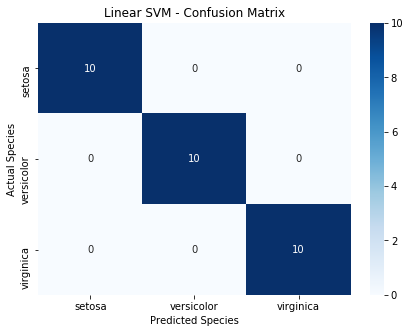

In [9]:

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Calculate accuracy
accuracy_linear = accuracy_score(y_test, y_pred_linear)

print("Linear SVM Accuracy:", accuracy_linear)

# Classification report
print("\nClassification Report:\n")
print(
    classification_report(
        y_test,
        y_pred_linear,
        target_names=iris.target_names
    )
)

# Calculate confusion matrix
cm_linear = confusion_matrix(y_test, y_pred_linear)

# Visualize confusion matrix using Seaborn
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_linear,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Linear SVM - Confusion Matrix")
plt.show()


In [11]:

# Create RBF SVM model
svm_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma=0.1
)

# Train the model
svm_rbf.fit(X_train_scaled, y_train)

# Make predictions
y_pred_rbf = svm_rbf.predict(X_test_scaled)

# Calculate accuracy
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

print("RBF SVM Accuracy:", accuracy_rbf)

# Classification report
print("\nClassification Report:\n")
print(
    classification_report(
        y_test,
        y_pred_rbf,
        target_names=iris.target_names
    )
)


RBF SVM Accuracy: 0.9666666666666667

Classification Report:

             precision    recall  f1-score   support

     setosa       1.00      1.00      1.00        10
 versicolor       1.00      0.90      0.95        10
  virginica       0.91      1.00      0.95        10

avg / total       0.97      0.97      0.97        30



In [16]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Create the Polynomial SVM model
svm_poly = SVC(
    kernel="poly",
    degree=3,
    C=1.0,
    gamma=0.1
)

# Train the model
svm_poly.fit(X_train_scaled, y_train)

# Make predictions
y_pred_poly = svm_poly.predict(X_test_scaled)

# Calculate accuracy
accuracy_poly = accuracy_score(y_test, y_pred_poly)

print("Polynomial SVM Accuracy:", accuracy_poly)

# Classification report
print("\nClassification Report:\n")
print(
    classification_report(
        y_test,
        y_pred_poly,
        target_names=iris.target_names
    )
)


Polynomial SVM Accuracy: 0.8

Classification Report:

             precision    recall  f1-score   support

     setosa       1.00      1.00      1.00        10
 versicolor       0.62      1.00      0.77        10
  virginica       1.00      0.40      0.57        10

avg / total       0.88      0.80      0.78        30



In [17]:

results = pd.DataFrame({
    "Model": ["Linear SVM", "Polynomial SVM", "RBF SVM"],
    "Accuracy": [
        accuracy_linear,
        accuracy_poly,
        accuracy_rbf
    ]
})

display(results.sort_values("Accuracy", ascending=False))


,Accuracy,Model
0,1.000000,Linear SVM
2,0.966667,RBF SVM
1,0.800000,Polynomial SVM


In [18]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import pandas as pd

experiments = []

for c_value in [0.1, 1, 10, 100]:
    for gamma_value in [0.01, 0.1, 1]:

        model = SVC(
            kernel="rbf",
            C=c_value,
            gamma=gamma_value
        )

        model.fit(X_train_scaled, y_train)

        train_pred = model.predict(X_train_scaled)
        test_pred = model.predict(X_test_scaled)

        experiments.append({
            "C": c_value,
            "Gamma": gamma_value,
            "Train Accuracy": accuracy_score(
                y_train, train_pred
            ),
            "Test Accuracy": accuracy_score(
                y_test, test_pred
            )
        })

tuning_results = pd.DataFrame(experiments)

display(
    tuning_results.sort_values(
        by="Test Accuracy",
        ascending=False
    ).reset_index(drop=True)
)


,C,Gamma,Test Accuracy,Train Accuracy
0,0.1,1.00,0.966667,0.958333
1,1.0,0.10,0.966667,0.983333
2,10.0,0.01,0.966667,0.983333
3,10.0,0.10,0.966667,0.983333
4,10.0,1.00,0.966667,0.991667
5,100.0,0.01,0.966667,0.958333
6,100.0,0.10,0.966667,0.983333
7,1.0,1.00,0.933333,0.975000
8,100.0,1.00,0.933333,1.000000
9,0.1,0.01,0.866667,0.875000


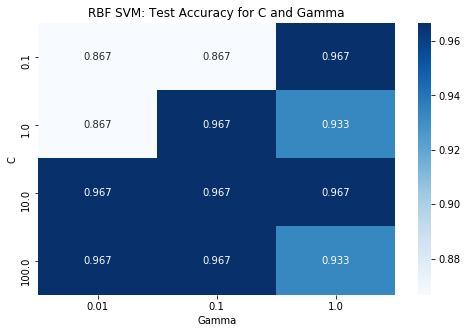

In [19]:

import matplotlib.pyplot as plt
import seaborn as sns

accuracy_pivot = tuning_results.pivot(
    index="C",
    columns="Gamma",
    values="Test Accuracy"
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    accuracy_pivot,
    annot=True,
    fmt=".3f",
    cmap="Blues"
)

plt.title("RBF SVM: Test Accuracy for C and Gamma")
plt.xlabel("Gamma")
plt.ylabel("C")
plt.show()


In [20]:

# Select the best combination from our experiment table
best_row = tuning_results.sort_values(
    by="Test Accuracy",
    ascending=False
).iloc[0]

best_C = best_row["C"]
best_gamma = best_row["Gamma"]

print("Selected C:", best_C)
print("Selected Gamma:", best_gamma)

# Train the selected RBF model
final_svm = SVC(
    kernel="rbf",
    C=best_C,
    gamma=best_gamma
)

final_svm.fit(X_train_scaled, y_train)

# Make final predictions
y_pred_final = final_svm.predict(X_test_scaled)

print(
    "\nFinal Test Accuracy:",
    accuracy_score(y_test, y_pred_final)
)

print("\nFinal Classification Report:\n")
print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=iris.target_names
    )
)


Selected C: 0.1
Selected Gamma: 1.0

Final Test Accuracy: 0.9666666666666667

Final Classification Report:

             precision    recall  f1-score   support

     setosa       1.00      1.00      1.00        10
 versicolor       1.00      0.90      0.95        10
  virginica       0.91      1.00      0.95        10

avg / total       0.97      0.97      0.97        30



In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Generate a nonlinear dataset
X, y = make_circles(
    n_samples=500,
    noise=0.08,
    factor=0.4,
    random_state=42
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Classes:", np.unique(y))


Features shape: (500, 2)
Target shape: (500,)
Classes: [0 1]


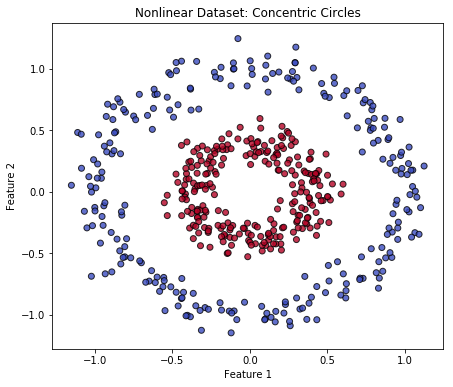

In [23]:

plt.figure(figsize=(7, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="black",
    alpha=0.8
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinear Dataset: Concentric Circles")
plt.show()


In [25]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)


Training shape: (400, 2)
Testing shape: (100, 2)


In [26]:

svm_linear = SVC(
    kernel="linear",
    C=1.0
)

svm_linear.fit(X_train_scaled, y_train)

y_pred_linear = svm_linear.predict(X_test_scaled)

print(
    "Linear SVM Accuracy:",
    accuracy_score(y_test, y_pred_linear)
)


Linear SVM Accuracy: 0.6


In [27]:

svm_poly = SVC(
    kernel="poly",
    degree=3,
    C=1.0,
    gamma=0.1
)

svm_poly.fit(X_train_scaled, y_train)

y_pred_poly = svm_poly.predict(X_test_scaled)

accuracy_poly = accuracy_score(y_test, y_pred_poly)

print("Polynomial SVM Accuracy:", accuracy_poly)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_poly))


Polynomial SVM Accuracy: 0.59

Classification Report:

             precision    recall  f1-score   support

          0       1.00      0.18      0.31        50
          1       0.55      1.00      0.71        50

avg / total       0.77      0.59      0.51       100



In [28]:

svm_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma=0.1
)

svm_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = svm_rbf.predict(X_test_scaled)

accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

print("RBF SVM Accuracy:", accuracy_rbf)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rbf))


RBF SVM Accuracy: 1.0

Classification Report:

             precision    recall  f1-score   support

          0       1.00      1.00      1.00        50
          1       1.00      1.00      1.00        50

avg / total       1.00      1.00      1.00       100



,Kernel,Test Accuracy
0,Linear,0.60
1,Polynomial,0.59
2,RBF,1.00


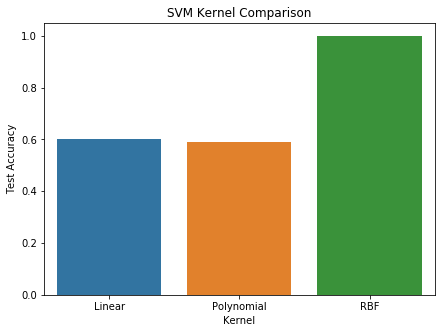

In [29]:

results = pd.DataFrame({
    "Kernel": ["Linear", "Polynomial", "RBF"],
    "Test Accuracy": [
        accuracy_score(y_test, y_pred_linear),
        accuracy_poly,
        accuracy_rbf
    ]
})

display(results)

plt.figure(figsize=(7, 5))
sns.barplot(
    data=results,
    x="Kernel",
    y="Test Accuracy"
)

plt.ylim(0, 1.05)
plt.title("SVM Kernel Comparison")
plt.show()


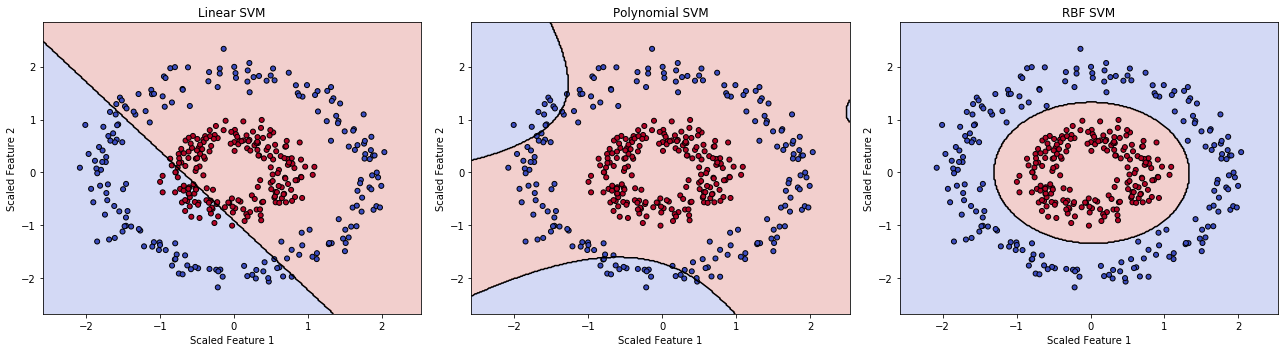

In [30]:

def plot_decision_boundary(model, X_data, y_data, title):
    x_min, x_max = X_data[:, 0].min() - 0.5, X_data[:, 0].max() + 0.5
    y_min, y_max = X_data[:, 1].min() - 0.5, X_data[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.contourf(
        xx, yy, Z,
        alpha=0.25,
        cmap="coolwarm"
    )

    plt.contour(
        xx, yy, Z,
        levels=[0.5],
        colors="black",
        linewidths=1.5
    )

    plt.scatter(
        X_data[:, 0],
        X_data[:, 1],
        c=y_data,
        cmap="coolwarm",
        edgecolors="black",
        s=25
    )

    plt.title(title)
    plt.xlabel("Scaled Feature 1")
    plt.ylabel("Scaled Feature 2")


plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plot_decision_boundary(
    svm_linear,
    X_train_scaled,
    y_train,
    "Linear SVM"
)

plt.subplot(1, 3, 2)
plot_decision_boundary(
    svm_poly,
    X_train_scaled,
    y_train,
    "Polynomial SVM"
)

plt.subplot(1, 3, 3)
plot_decision_boundary(
    svm_rbf,
    X_train_scaled,
    y_train,
    "RBF SVM"
)

plt.tight_layout()
plt.show()


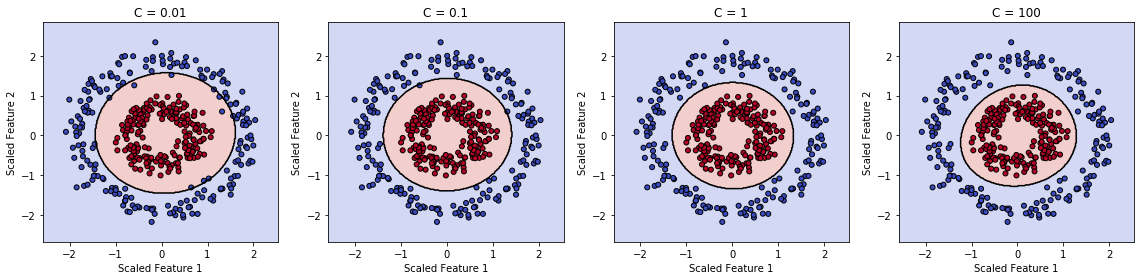

In [31]:

C_values = [0.01, 0.1, 1, 100]

plt.figure(figsize=(16, 4))

for i, c_value in enumerate(C_values):
    model = SVC(
        kernel="rbf",
        C=c_value,
        gamma=0.1
    )

    model.fit(X_train_scaled, y_train)

    plt.subplot(1, 4, i + 1)

    plot_decision_boundary(
        model,
        X_train_scaled,
        y_train,
        "C = {}".format(c_value)
    )

plt.tight_layout()
plt.show()


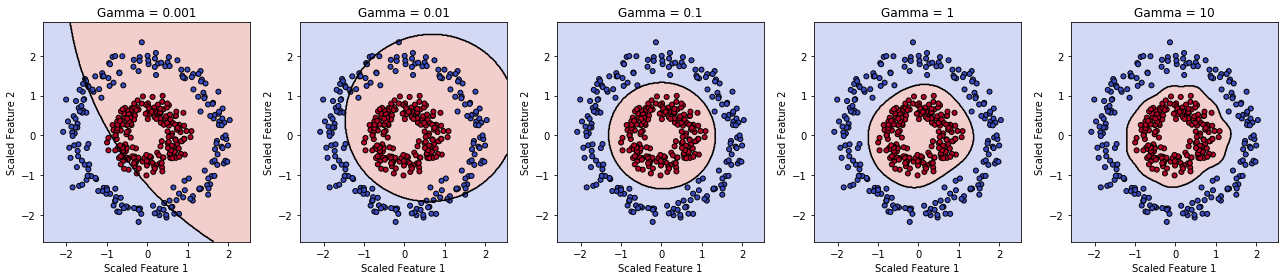

In [32]:

gamma_values = [0.001, 0.01, 0.1, 1, 10]

plt.figure(figsize=(18, 4))

for i, gamma_value in enumerate(gamma_values):
    model = SVC(
        kernel="rbf",
        C=1.0,
        gamma=gamma_value
    )

    model.fit(X_train_scaled, y_train)

    plt.subplot(1, 5, i + 1)

    plot_decision_boundary(
        model,
        X_train_scaled,
        y_train,
        "Gamma = {}".format(gamma_value)
    )

plt.tight_layout()
plt.show()
